In [1]:
import pandas as pd

train = pd.read_csv("../data/raw/fraudTrain.csv", index_col=0)
test = pd.read_csv("../data/raw/fraudTest.csv", index_col=0)

In [2]:
print("Train:", train.shape)
print("Test:", test.shape)

Train: (1296675, 22)
Test: (555719, 22)


In [3]:
train.head()

,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [4]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 22 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   trans_date_trans_time  1296675 non-null  str    
 1   cc_num                 1296675 non-null  int64  
 2   merchant               1296675 non-null  str    
 3   category               1296675 non-null  str    
 4   amt                    1296675 non-null  float64
 5   first                  1296675 non-null  str    
 6   last                   1296675 non-null  str    
 7   gender                 1296675 non-null  str    
 8   street                 1296675 non-null  str    
 9   city                   1296675 non-null  str    
 10  state                  1296675 non-null  str    
 11  zip                    1296675 non-null  int64  
 12  lat                    1296675 non-null  float64
 13  long                   1296675 non-null  float64
 14  city_pop               129667

In [5]:
print(train["is_fraud"].value_counts())
print("Fraud rate:", round(train["is_fraud"].mean() * 100, 2), "%")

is_fraud
0    1289169
1       7506
Name: count, dtype: int64
Fraud rate: 0.58 %


In [6]:
train["trans_date_trans_time"] = pd.to_datetime(train["trans_date_trans_time"])
test["trans_date_trans_time"] = pd.to_datetime(test["trans_date_trans_time"])

print("Train:", train["trans_date_trans_time"].min(), "to", train["trans_date_trans_time"].max())
print("Test: ", test["trans_date_trans_time"].min(), "to", test["trans_date_trans_time"].max())

Train: 2019-01-01 00:00:18 to 2020-06-21 12:13:37
Test:  2020-06-21 12:14:25 to 2020-12-31 23:59:34


In [7]:
(train.groupby("category")["is_fraud"]
      .mean()
      .sort_values(ascending=False)
      .mul(100).round(2))

category
shopping_net      1.76
misc_net          1.45
grocery_pos       1.41
shopping_pos      0.72
gas_transport     0.47
misc_pos          0.31
grocery_net       0.29
travel            0.29
entertainment     0.25
personal_care     0.24
kids_pets         0.21
food_dining       0.17
home              0.16
health_fitness    0.15
Name: is_fraud, dtype: float64

<Axes: title={'center': 'Fraud rate (%) by hour'}, xlabel='hour'>

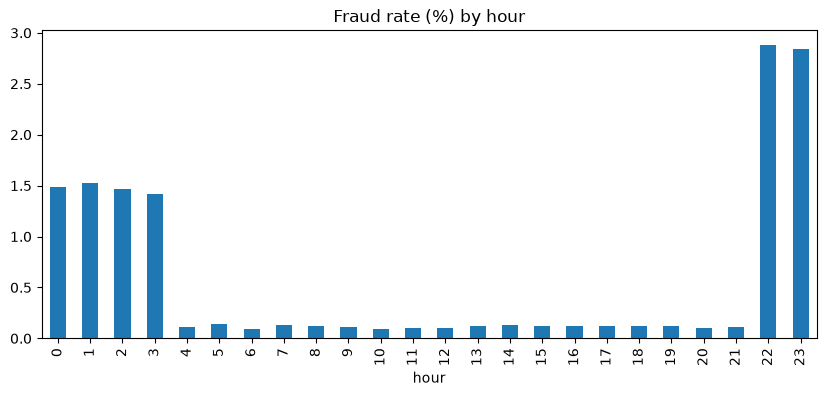

In [8]:
train["hour"] = train["trans_date_trans_time"].dt.hour
(train.groupby("hour")["is_fraud"].mean().mul(100).round(2)).plot(kind="bar", figsize=(10, 4), title="Fraud rate (%) by hour")

## Key findings
- Fraud rate is 0.58% → accuracy is useless; use precision, recall, and money lost
- Train (2019-01 to 2020-06) and test (2020-06 to 2020-12) are split by time → no future leakage
- Online categories (shopping_net, misc_net) have ~3x the average fraud rate
- Fraud is ~25x higher at night (10 PM to 3 AM) than during the day
- Data contains PII (names, address, DOB) → don't use as features; convert DOB to age
- cc_num is an ID → use for grouping history, not as a feature